## Model 6: XGBoost Regressor (Ensemble)

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load Dataset

In [29]:
df = pd.read_csv("dataset/gas_turbine_processed.csv")
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,82.028


### 2. Train Test Split

In [30]:
X = df.drop('NOX', axis=1)
y = df['NOX']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

### 3. Base Model Training (Default Parameters)

In [31]:
base_xgb = XGBRegressor(random_state=42, n_jobs=-1)
base_xgb.fit(X_train, y_train)

y_train_base = base_xgb.predict(X_train)
y_test_base = base_xgb.predict(X_test)

### 4. Base Model Evaluation Metrics (Train & Test)

In [32]:
base_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_base),
        mean_squared_error(y_train, y_train_base),
        np.sqrt(mean_squared_error(y_train, y_train_base)),
        r2_score(y_train, y_train_base)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_base),
        mean_squared_error(y_test, y_test_base),
        np.sqrt(mean_squared_error(y_test, y_test_base)),
        r2_score(y_test, y_test_base)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Base XGBoost Metrics:")
display(base_metrics)

Base XGBoost Metrics:


,Train Set,Test Set
MAE,2.2383,2.9459
MSE,10.0242,18.7126
RMSE,3.1661,4.3258
R2,0.9270,0.8588


### 5. Hyperparameter Tuning (500 Trees, lr=0.04, depth=8, subsample=0.8)

In [24]:
tuned_xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.04,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    random_state=42,
    n_jobs=-1
)
tuned_xgb.fit(X_train, y_train)

print("Best Parameters:      ", {'n_estimators': 500, 'learning_rate': 0.04, 'max_depth': 8, 'subsample': 0.8, 'colsample_bytree': 0.8})
print("Best Estimator Model: ", tuned_xgb)

Best Parameters:       {'n_estimators': 500, 'learning_rate': 0.04, 'max_depth': 8, 'subsample': 0.8, 'colsample_bytree': 0.8}
Best Estimator Model:  XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.04, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=3, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)


### 6. Tuned Model Evaluation Metrics (Train & Test)

In [25]:
y_train_tuned = tuned_xgb.predict(X_train)
y_test_tuned = tuned_xgb.predict(X_test)

tuned_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_tuned),
        mean_squared_error(y_train, y_train_tuned),
        np.sqrt(mean_squared_error(y_train, y_train_tuned)),
        r2_score(y_train, y_train_tuned)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_tuned),
        mean_squared_error(y_test, y_test_tuned),
        np.sqrt(mean_squared_error(y_test, y_test_tuned)),
        r2_score(y_test, y_test_tuned)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Tuned XGBoost Metrics:")
display(tuned_metrics)

Tuned XGBoost Metrics:


,Train Set,Test Set
MAE,1.6912,2.6448
MSE,5.8255,15.6882
RMSE,2.4136,3.9608
R2,0.9576,0.8816


### 7. Comparison: Base vs Tuned & R2 Increase

In [26]:
xgb_comparison = pd.DataFrame({
    'Base XGBoost': base_metrics['Test Set'],
    'Tuned XGBoost': tuned_metrics['Test Set']
})
display(xgb_comparison)

base_r2 = base_metrics.loc['R2', 'Test Set']
tuned_r2 = tuned_metrics.loc['R2', 'Test Set']
diff_r2 = tuned_r2 - base_r2

print(f"Base Test R2:          {base_r2:.4f}")
print(f"Tuned Test R2:         {tuned_r2:.4f}")
print(f"Increase in R2 Score:  {diff_r2:+.4f}")

,Base XGBoost,Tuned XGBoost
MAE,2.9459,2.6448
MSE,18.7126,15.6882
RMSE,4.3258,3.9608
R2,0.8588,0.8816


Base Test R2:          0.8588
Tuned Test R2:         0.8816
Increase in R2 Score:  +0.0228


### 8. Plots: Feature Importances & Predicted vs Actual

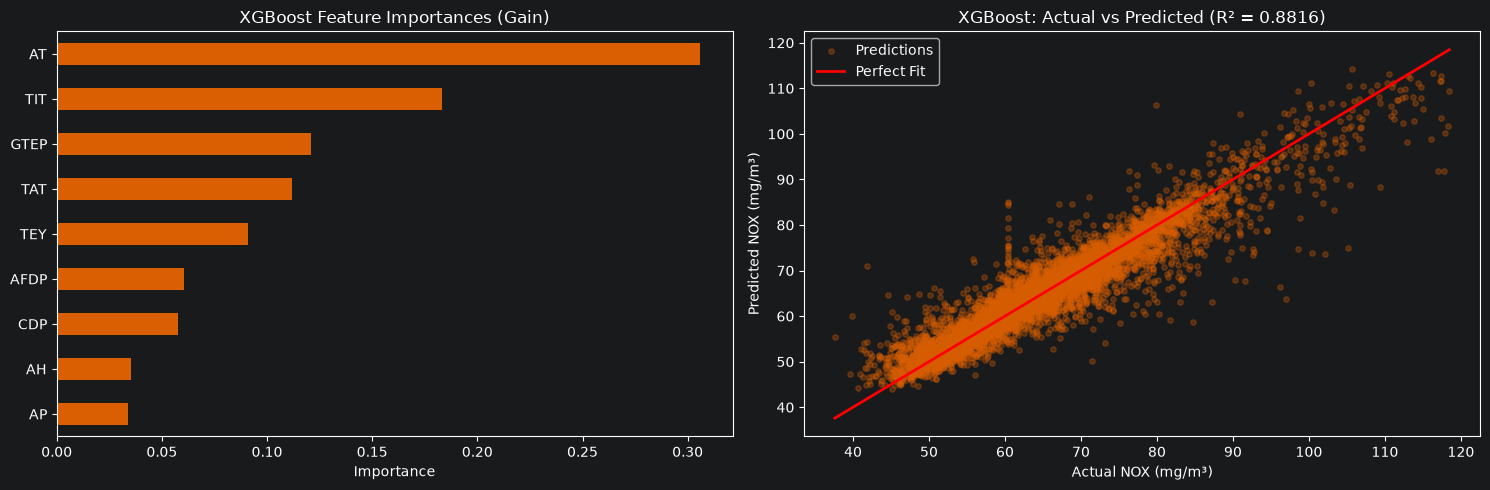

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Feature importances
feat_imp = pd.Series(tuned_xgb.feature_importances_, index=X.columns).sort_values(ascending=True)
feat_imp.plot(kind='barh', ax=axes[0], color='#d95f02')
axes[0].set_title("XGBoost Feature Importances (Gain)")
axes[0].set_xlabel("Importance")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_tuned, color='#d95f02', alpha=0.3, s=15, label='Predictions')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit')
axes[1].set_title(f"XGBoost: Actual vs Predicted (R² = {tuned_r2:.4f})")
axes[1].set_xlabel("Actual NOX (mg/m³)")
axes[1].set_ylabel("Predicted NOX (mg/m³)")
axes[1].legend()

plt.tight_layout()
plt.show()